In [1]:
import sys
from functools import partial

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import datasets, transforms, models

sys.path.insert(0, "Dino")
import Dino.vision_transformer as vits
from Dino.vision_transformer import Attention
from Dino.fibottention import get_mask_attn_wythoff

device = "cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"
print("device:", device)

TRAIN_ROOT, TEST_ROOT, MODELS = "data/train", "data/test", "Models"
GLOBAL_SIZE = 160
K = 20

device: mps


In [2]:
def make_mask(pattern, heads, n_patches, seed=0):
    if pattern == "fib":
        return get_mask_attn_wythoff(heads, n_patches, True, True, seed, add_class_token=True)
    side = int(round(n_patches ** 0.5))
    r, c = torch.arange(n_patches) // side, torch.arange(n_patches) % side
    dr, dc = (r[:, None] - r[None]).abs(), (c[:, None] - c[None]).abs()
    if pattern == "window":
        m = (dr <= 1) & (dc <= 1)
    elif pattern == "dilated":
        m = (dr <= 2) & (dc <= 2) & (dr % 2 == 0) & (dc % 2 == 0)
    elif pattern == "random":
        fib = get_mask_attn_wythoff(heads, n_patches, True, True, 0)[:, 1:, 1:]
        g = torch.Generator().manual_seed(seed)
        m = torch.rand(heads, n_patches, n_patches, generator=g) < fib.mean()
    else:
        raise ValueError(pattern)
    mask = torch.ones(heads, n_patches + 1, n_patches + 1)
    mask[:, 1:, 1:] = m.expand(heads, n_patches, n_patches).float()
    return mask


class MaskedAttention(Attention):
    def __init__(self, dim, num_heads, pattern, depth_id, **kwargs):
        super().__init__(dim, num_heads=num_heads, **kwargs)
        self.pattern, self.depth_id, self.masks = pattern, depth_id, {}

    def forward(self, x):
        B, N, C = x.shape
        key = (N, str(x.device))
        if key not in self.masks:
            self.masks[key] = make_mask(self.pattern, self.num_heads, N - 1, seed=self.depth_id).to(x.device)
        qkv = self.qkv(x).reshape(B, N, 3, self.num_heads, C // self.num_heads).permute(2, 0, 3, 1, 4)
        q, k, v = qkv[0], qkv[1], qkv[2]
        attn = ((q @ k.transpose(-2, -1)) * self.scale).masked_fill(self.masks[key] == 0, float("-inf")).softmax(dim=-1)
        x = (attn @ v).transpose(1, 2).reshape(B, N, C)
        return self.proj(x), attn


def load_vit(path, pattern=None):
    sd = torch.load(path, map_location="cpu")
    depth = len({k.split(".")[1] for k in sd if k.startswith("blocks.")})
    img_size = int(round((sd["pos_embed"].shape[1] - 1) ** 0.5)) * 16
    model = vits.VisionTransformer(
        patch_size=16, img_size=[img_size], embed_dim=192, depth=depth, num_heads=3,
        mlp_ratio=4, qkv_bias=True, norm_layer=partial(nn.LayerNorm, eps=1e-6))
    if pattern is not None:
        for i, blk in enumerate(model.blocks):
            blk.attn = MaskedAttention(192, 3, pattern, depth_id=i, qkv_bias=True)
    model.load_state_dict(sd)
    return model.to(device).eval()


class SceneClassifier(nn.Module):
    def __init__(self, num_classes, dropout=0.3):
        super().__init__()
        self.features = models.efficientnet_b0(weights=None).features
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.classifier = nn.Sequential(nn.Flatten(), nn.Dropout(dropout), nn.Linear(1280, num_classes))

    def forward(self, x):
        return self.classifier(self.pool(self.features(x)))

In [3]:
IMAGENET = transforms.Normalize((0.485, 0.456, 0.406), (0.229, 0.224, 0.225))
to_rgb = transforms.Lambda(lambda im: im.convert("RGB"))

def dino_transform(imagenet_norm):
    steps = [to_rgb, transforms.Resize(GLOBAL_SIZE), transforms.CenterCrop(GLOBAL_SIZE), transforms.ToTensor()]
    return transforms.Compose(steps + ([IMAGENET] if imagenet_norm else []))

DINO_MODELS = {
    "DINO":         ("dino_vit_tiny_teacher.pth",         None,      True),
    "Fib-DINO":     ("fib_dino_vit_tiny_teacher.pth",     "fib",     True),
    "Random-DINO":  ("random_dino_vit_tiny_teacher.pth",  "random",  False),
    "Window-DINO":  ("window_dino_vit_tiny_teacher.pth",  "window",  False),
    "Dilated-DINO": ("dilated_dino_vit_tiny_teacher.pth", "dilated", False),
}

class_names = datasets.ImageFolder(TEST_ROOT).classes
n_cls = len(class_names)
chance = 1 / n_cls
print(f"{n_cls} classes, {len(datasets.ImageFolder(TEST_ROOT))} test images")

16 classes, 400 test images


In [4]:
@torch.no_grad()
def predict(model, loader):
    preds, labels = [], []
    for x, y in loader:
        preds.append(model(x.to(device)).argmax(1).cpu())
        labels.append(y)
    return torch.cat(preds), torch.cat(labels)

ckpt = torch.load(f"{MODELS}/best_efficientnet_b0_baseline.pt", map_location="cpu", weights_only=False)
assert ckpt["class_names"] == class_names
cfg = ckpt["config"]["data"]
effnet = SceneClassifier(n_cls)
effnet.load_state_dict(ckpt["model_state"])
effnet = effnet.to(device).eval()

eff_t = transforms.Compose([to_rgb, transforms.Resize((cfg["img_size"], cfg["img_size"])),
                            transforms.ToTensor(), transforms.Normalize(cfg["mean"], cfg["std"])])
test_loader = torch.utils.data.DataLoader(datasets.ImageFolder(TEST_ROOT, transform=eff_t), batch_size=64)

eff_pred, test_y = predict(effnet, test_loader)
results = {"EfficientNet-B0": {"pred": eff_pred, "acc": (eff_pred == test_y).float().mean().item()}}
print(f"EfficientNet-B0 test accuracy: {results['EfficientNet-B0']['acc']:.3f}")

EfficientNet-B0 test accuracy: 0.918


In [5]:
@torch.no_grad()
def extract(backbone, folder, transform):
    feats, labels = [], []
    for x, y in torch.utils.data.DataLoader(datasets.ImageFolder(folder, transform=transform), batch_size=64):
        feats.append(F.normalize(backbone(x.to(device)), dim=1).cpu())
        labels.append(y)
    return torch.cat(feats), torch.cat(labels)

for name, (file, pattern, imagenet_norm) in DINO_MODELS.items():
    backbone = load_vit(f"{MODELS}/{file}", pattern)
    t = dino_transform(imagenet_norm)
    train_f, train_y = extract(backbone, TRAIN_ROOT, t)
    test_f, y = extract(backbone, TEST_ROOT, t)
    assert torch.equal(y, test_y)

    knn_pred = train_y[(test_f @ train_f.T).topk(K, dim=1).indices].mode(dim=1).values
    results[name] = {"pred": knn_pred, "acc": (knn_pred == test_y).float().mean().item()}
    print(f"{name:<13} {K}-NN test accuracy: {results[name]['acc']:.3f}")

DINO          20-NN test accuracy: 0.395
Fib-DINO      20-NN test accuracy: 0.345
Random-DINO   20-NN test accuracy: 0.322
Window-DINO   20-NN test accuracy: 0.350
Dilated-DINO  20-NN test accuracy: 0.350


model             test acc   (chance = 0.062)
EfficientNet-B0      0.918
DINO                 0.395
Window-DINO          0.350
Dilated-DINO         0.350
Fib-DINO             0.345
Random-DINO          0.322

EfficientNet-B0: supervised predictions. DINO models: 20-NN on frozen features.


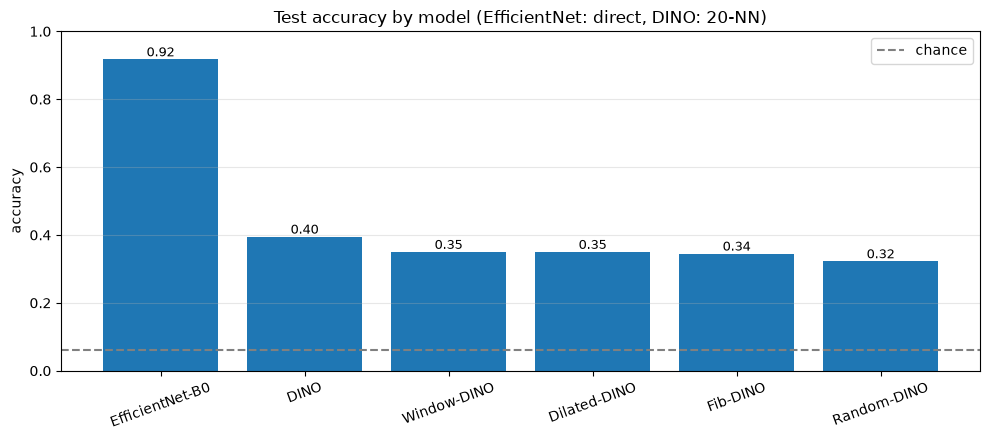

In [6]:
names = sorted(results, key=lambda n: -results[n]["acc"])

print(f"{'model':<16}{'test acc':>10}   (chance = {chance:.3f})")
for n in names:
    print(f"{n:<16}{results[n]['acc']:>10.3f}")
print(f"\nEfficientNet-B0: supervised predictions. DINO models: {K}-NN on frozen features.")

fig, ax = plt.subplots(figsize=(10, 4.5))
bars = ax.bar(names, [results[n]["acc"] for n in names])
ax.bar_label(bars, fmt="%.2f", fontsize=9)
ax.axhline(chance, color="gray", ls="--", label="chance")
ax.tick_params(axis="x", rotation=20)
ax.set(ylabel="accuracy", ylim=(0, 1), title=f"Test accuracy by model (EfficientNet: direct, DINO: {K}-NN)")
ax.legend(loc="upper right")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

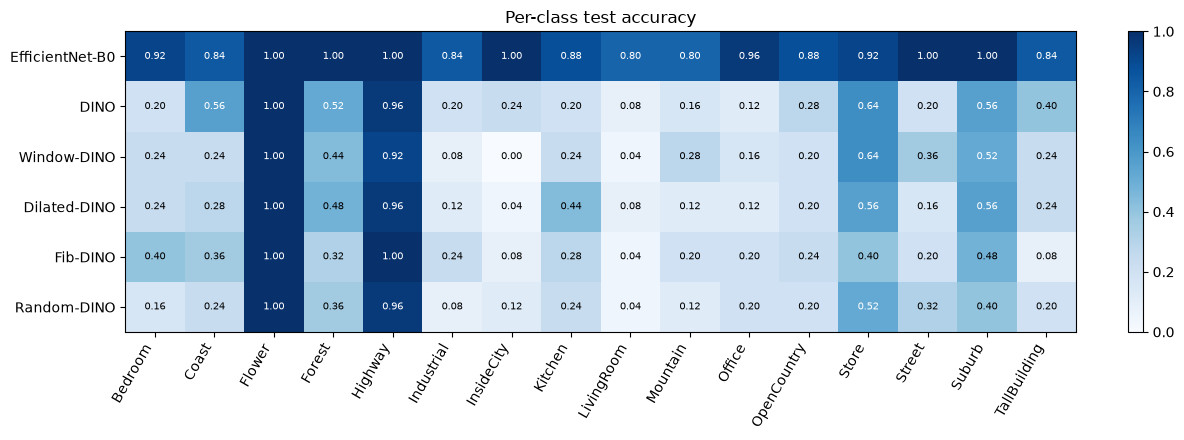

In [7]:

per_class = np.array([[(results[n]["pred"][test_y == c] == c).float().mean().item() for c in range(n_cls)]
                      for n in names])

fig, ax = plt.subplots(figsize=(12, 4.5))
im = ax.imshow(per_class, cmap="Blues", vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(n_cls), class_names, rotation=60, ha="right")
ax.set_yticks(range(len(names)), names)
for i in range(len(names)):
    for j in range(n_cls):
        ax.text(j, i, f"{per_class[i, j]:.2f}", ha="center", va="center", fontsize=7,
                color="white" if per_class[i, j] > 0.5 else "black")
ax.set_title("Per-class test accuracy")
fig.colorbar(im, ax=ax, fraction=0.03)
plt.tight_layout()
plt.show()